# XXZ模型：クエンチ後のスタッガード磁化$m_s(t)$

初期状態のNéel状態$\ket{0101\cdots}$（$\Delta\to\infty$の基底状態）から、XXZ模型のハミルトニアン$H$で時間発展させたときのスタッガード磁化$m_s(t)$を、厳密対角化・Jordan-Wigner変換（$\Delta=0$のみ）・Trotter分解（量子回路）で求めて比較する。模型の定義は [00_model.ipynb](00_model.ipynb)、各手法のXXZ模型への適用は [01_exact_diag](01_exact_diag.ipynb)・[02_jordan_wigner](02_jordan_wigner.ipynb)・[03_trotter](03_trotter.ipynb)・[04_vqe](04_vqe.ipynb)、手法の一般論は [methods/](../../methods/) を参照。

TFIMでは、Jordan-Wigner変換で任意の$h$について大きな$n$の時間発展を計算できた。XXZ模型では、Jordan-Wigner変換が使えるのは$\Delta=0$だけで、Bethe仮説も時間発展には簡単には使えない（[02_jordan_wigner.ipynb](02_jordan_wigner.ipynb)の7節）。$\Delta\neq0$では、厳密対角化と量子回路が主な手法になる。境界条件は開放境界条件とする。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0

# 厳密対角化（src/qmb/operators.py, ed.py）と XXZ 模型の定義（src/qmb/models.py）
from qmb.operators import neel_state
from qmb.ed import time_evolve_expectation, sector_basis, project_to_sector
from qmb.models import (xxz_hamiltonian as hamiltonian, staggered_magnetization,
                        xxz_hamiltonian_sector, staggered_magnetization_sector)
from qiskit.quantum_info import Statevector

# 各手法の XXZ 模型への適用（src/qmb/models.py, circuits.py）
from qmb.models import xxz_ms_quench_ff as ms_jw
from qmb.circuits import xxz_op, staggered_op, neel_circuit, xxz_trotter_step, ms_trotter
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: xxz_trotter_step??）


def ms_ed(n, J, Delta, ts):
    # Néel 状態は全磁化 0（|1> が n/2 個）のブロックにあるので、そのブロックだけで時間発展させる
    m = n // 2
    psi0 = project_to_sector(neel_state(n), sector_basis(n, m))
    H = xxz_hamiltonian_sector(n, J, Delta, m).toarray()
    A = staggered_magnetization_sector(n, m).toarray()
    return time_evolve_expectation(H, psi0, A, ts)

## 1. 厳密対角化とJordan-Wigner変換の比較（$\Delta=0$）

$n=10$、$\Delta=0$で、厳密対角化（全空間の$1024\times1024$行列と、全磁化0のブロックの$252\times252$行列）とJordan-Wigner変換（$10\times10$行列）を比較する。

全空間とブロックの最大の差          = 1.28e-15
厳密対角化とJordan-Wigner変換の最大の差 = 1.55e-15


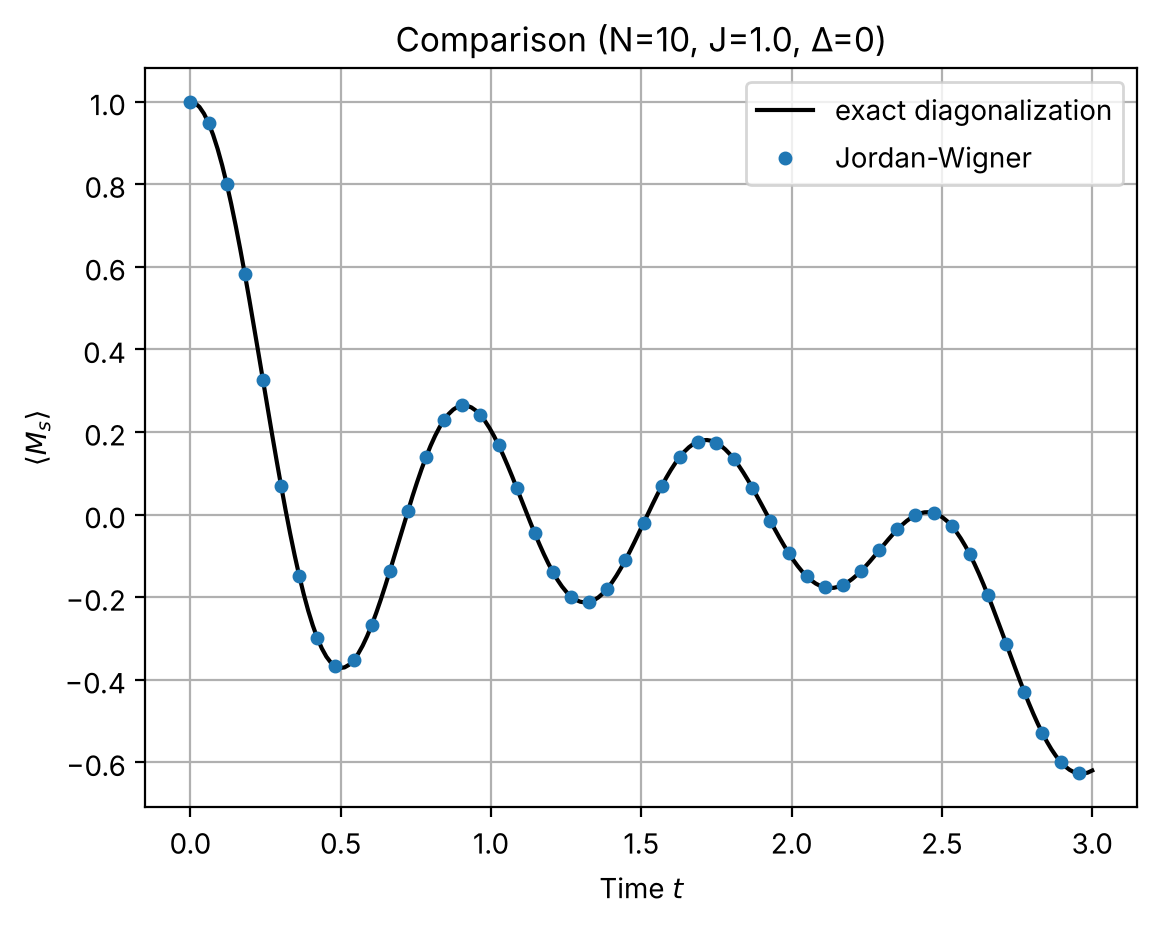

In [2]:
N = 10
J = 1.0
ts = np.linspace(0, 3, 200)

ms_full = time_evolve_expectation(hamiltonian(N, J, 0.0), neel_state(N), staggered_magnetization(N), ts)
ms_block = ms_ed(N, J, 0.0, ts)
ms_f = ms_jw(N, J, ts)
print(f"全空間とブロックの最大の差          = {np.max(np.abs(ms_full - ms_block)):.2e}")
print(f"厳密対角化とJordan-Wigner変換の最大の差 = {np.max(np.abs(ms_block - ms_f)):.2e}")

plt.plot(ts, ms_block, "k-", label="exact diagonalization")
plt.plot(ts[::4], ms_f[::4], "o", ms=4, label="Jordan-Wigner")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Comparison (N={N}, J={J}, Δ=0)")
plt.legend()
plt.grid()
plt.show()

3つの計算は数値誤差の範囲で一致している。

## 2. 大きな$n$での時間発展（$\Delta=0$）

$\Delta=0$ならJordan-Wigner変換で$n=400$も$400\times400$行列で計算できる。[02_jordan_wigner.ipynb](02_jordan_wigner.ipynb)の3節で求めた無限に長い鎖の結果$m_s(t) = J_0(8Jt)$と比べる。

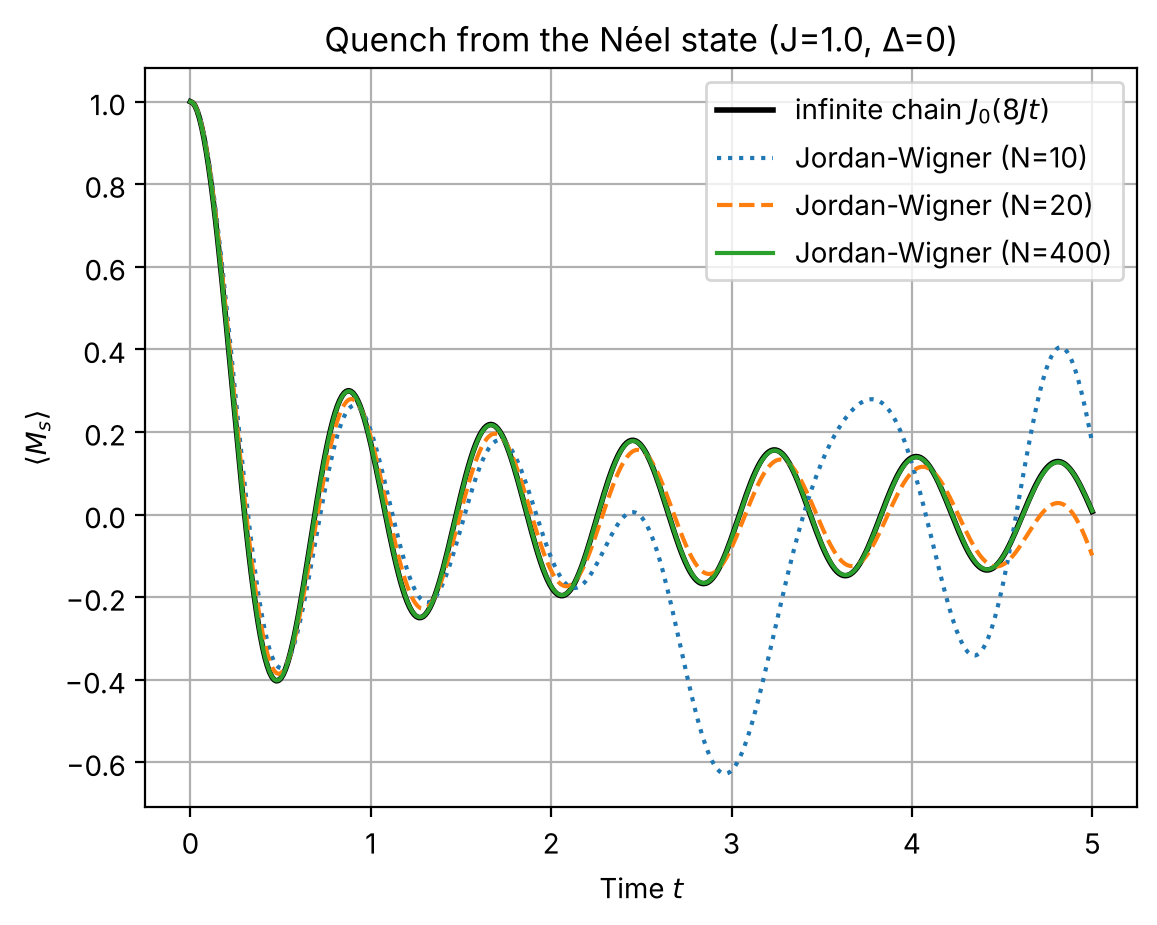

N=400 と J0(8Jt) の最大の差（0 ≤ t ≤ 5） = 2.28e-03


In [3]:
J = 1.0
ts = np.linspace(0, 5, 400)
plt.plot(ts, j0(8 * J * ts), "k-", lw=2, label=r"infinite chain $J_0(8Jt)$")
for N, ls in [(10, ":"), (20, "--"), (400, "-")]:
    plt.plot(ts, ms_jw(N, J, ts), ls, label=f"Jordan-Wigner (N={N})")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Quench from the Néel state (J={J}, Δ=0)")
plt.legend()
plt.grid()
plt.show()

ms_400 = ms_jw(400, J, ts)
print(f"N=400 と J0(8Jt) の最大の差（0 ≤ t ≤ 5） = {np.max(np.abs(ms_400 - j0(8 * J * ts))):.2e}")

$n=400$ではベッセル関数$J_0(8Jt)$とほぼ重なる（わずかな差は開放境界の端のサイトの寄与で、$1/n$に比例する）。$m_s(t)$は振動しながら$t^{-1/2}$で減衰し、反強磁性の秩序は失われていく。$n=10, 20$では、ある時刻から$J_0$から大きくずれる。これは、端で反射した励起（1粒子の分散$4J\cos k$の群速度は最大$4J$）が鎖の中を伝わってくる**有限サイズの効果**で、ずれ始める時刻は$n$に比例して遅くなる。

以下で$\Delta\neq0$を厳密対角化で調べるときも、信頼できるのはこの時刻までである。

## 3. 異方性$\Delta$への依存性

$\Delta\neq0$ではJordan-Wigner変換が使えないので、厳密対角化（全磁化0のブロック）で$n=14$まで計算する。どの時刻まで有限サイズの影響が小さいかを見るため、$n=12$と$n=14$を重ねて描く。

Δ=0.0: N=12 と N=14 の差が 0.02 を超える最初の時刻 t = 2.7


Δ=0.5: N=12 と N=14 の差が 0.02 を超える最初の時刻 t = 2.375


Δ=1.0: N=12 と N=14 の差が 0.02 を超える最初の時刻 t = 2.125


Δ=2.0: N=12 と N=14 の差が 0.02 を超える最初の時刻 t = 1.2000000000000002


Δ=4.0: N=12 と N=14 の差が 0.02 を超える最初の時刻 t = 1.3250000000000002


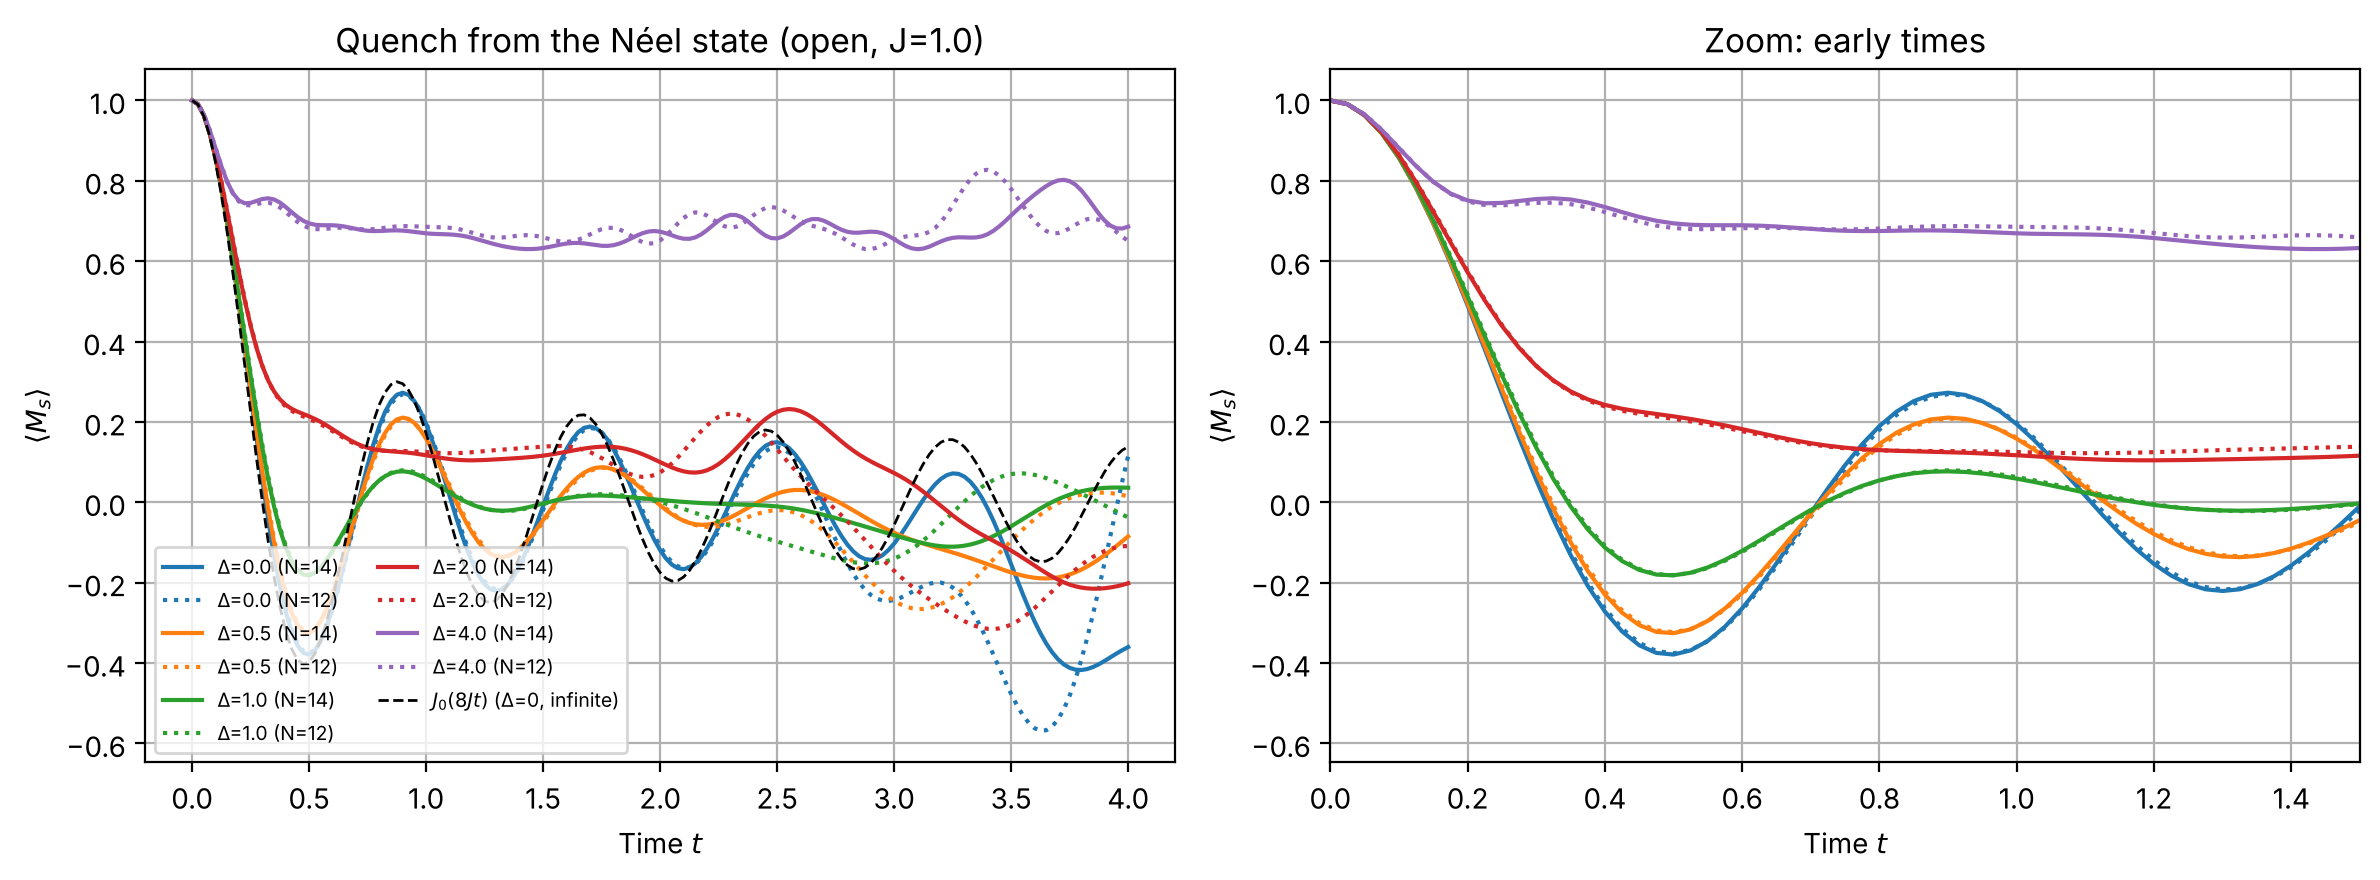

In [4]:
J = 1.0
ts = np.linspace(0, 4, 161)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for Delta, color in [(0.0, "C0"), (0.5, "C1"), (1.0, "C2"), (2.0, "C3"), (4.0, "C4")]:
    ms14 = ms_ed(14, J, Delta, ts)
    ms12 = ms_ed(12, J, Delta, ts)
    for ax in axes:
        ax.plot(ts, ms14, "-", color=color, label=f"Δ={Delta} (N=14)")
        ax.plot(ts, ms12, ":", color=color, label=f"Δ={Delta} (N=12)")
    print(f"Δ={Delta}: N=12 と N=14 の差が 0.02 を超える最初の時刻 t = "
          f"{ts[np.argmax(np.abs(ms14 - ms12) > 0.02)] if np.any(np.abs(ms14 - ms12) > 0.02) else '> 4'}")
axes[0].plot(ts, j0(8 * J * ts), "k--", lw=1, label=r"$J_0(8Jt)$ (Δ=0, infinite)")
axes[0].set_title(f"Quench from the Néel state (open, J={J})")
axes[1].set_xlim(0, 1.5)
axes[1].set_title("Zoom: early times")
for ax in axes:
    ax.set_xlabel("Time $t$")
    ax.set_ylabel(r"$\langle M_s \rangle$")
    ax.grid()
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

$n=12$と$n=14$がほぼ一致している時刻（$\Delta\le1$では$t\lesssim2$、$\Delta>1$では$t\lesssim1.2$）までが、無限に長い鎖の振る舞いをよく表していると考えられる。その範囲で次のことがわかる。

- **$\Delta<1$（臨界相）**：$m_s(t)$は符号を変えながら振動し、0のまわりで減衰する。$\Delta$が大きいほど振動が弱まり、減衰が速くなる（$\Delta=1$ではほとんど振動せずに0に近づく）。
- **$\Delta>1$（反強磁性相）**：$m_s$は最初に少し下がったあと、符号を変えずに正の値のまわりにとどまり、ゆっくりと減衰する。$\Delta$が大きいほどNéel状態は$H$の基底状態に近く、$XY$項による「隣どうしの入れ替え」はエネルギー$4J\Delta$のコストがかかるので起こりにくい。$\Delta=4$では、少なくとも$t\lesssim1.2$の範囲で$m_s$は$0.7$程度にとどまっている。
- **$n=2$との違い**：[01_exact_diag.ipynb](01_exact_diag.ipynb)の$n=2$では$m_s(t) = \cos(4Jt)$と$\Delta$によらなかったが、$n\ge3$では$\ket{1}$が隣り合ったり離れたりできるので、$\Delta$で振る舞いが大きく変わる。どの$\Delta$でも$t\to0$の振る舞いは同じで、$m_s(t)\approx1 - 16J^2t^2\cdot\frac{n-1}{n}$（短時間展開の2次の項は$XY$項だけで決まる。$n=2$では$\cos4Jt\approx1-8J^2t^2$、$n\to\infty$では$J_0(8Jt)\approx1-16J^2t^2$と一致する）である。

$t\to\infty$でどこに落ち着くか（熱平衡化するか）や、減衰の速さの$\Delta$依存性を正確に調べるには、より大きな$n$が必要になる。これはテンソルネットワーク（[methods/05_tebd.ipynb](../../methods/05_tebd.ipynb)）や量子回路の出番である。

## 4. Trotter分解（量子回路）との比較

$n=10$、$\Delta=0.5$で、Trotter分解の時間刻み$\delta t$を変えて厳密対角化と比較する。

δt = 0.20: m_s(t) の最大誤差 = 7.27e-02
δt = 0.05: m_s(t) の最大誤差 = 5.10e-03


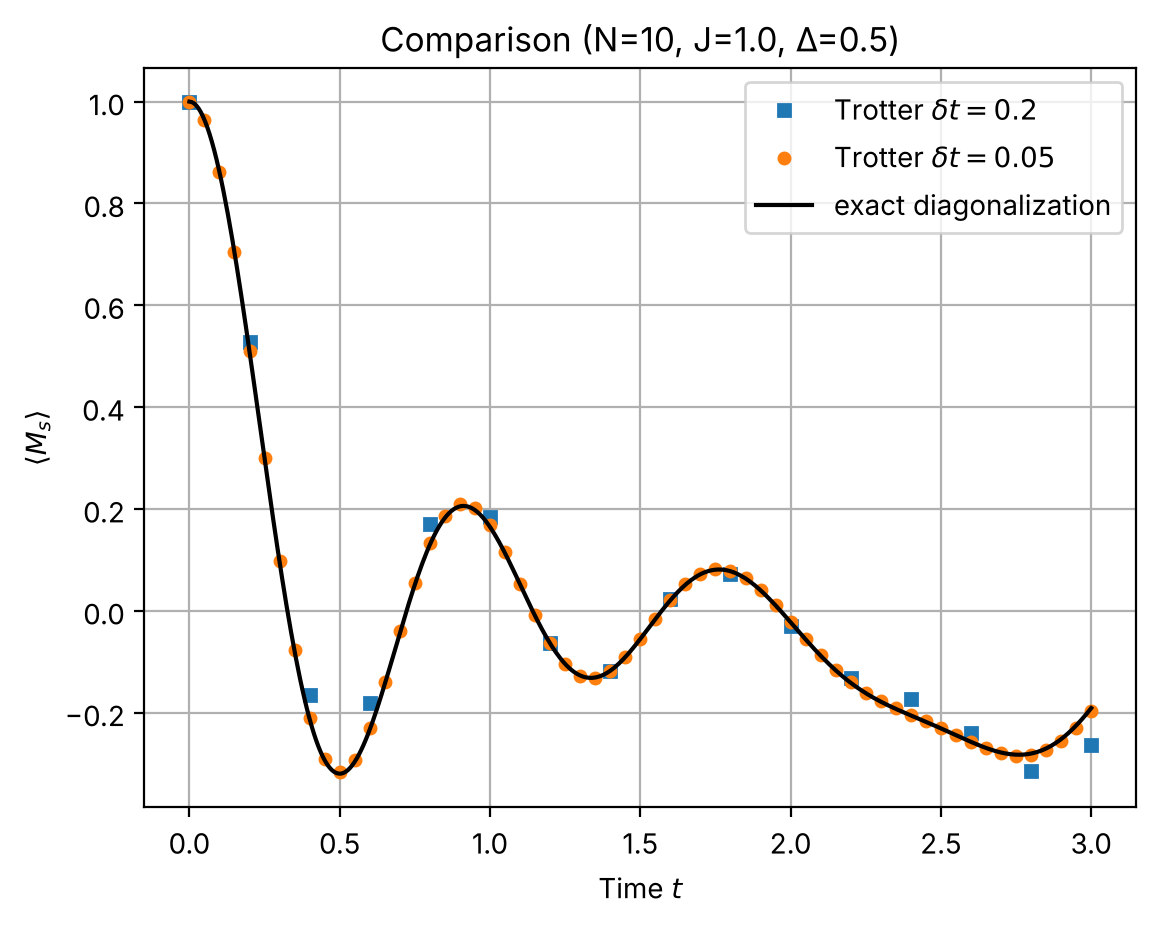

In [5]:
N = 10
J = 1.0
Delta = 0.5
t_max = 3

for r, mk in [(15, "s"), (60, "o")]:
    ts_r, ms_r = ms_trotter(N, J, Delta, t_max, r)
    ms_ex = ms_ed(N, J, Delta, ts_r)
    print(f"δt = {t_max / r:.2f}: m_s(t) の最大誤差 = {np.max(np.abs(ms_r - ms_ex)):.2e}")
    every = max(1, r // 50)
    plt.plot(ts_r[::every], ms_r[::every], mk, ms=4, label=rf"Trotter $\delta t={t_max / r}$")

ts = np.linspace(0, t_max, 400)
plt.plot(ts, ms_ed(N, J, Delta, ts), "k-", label="exact diagonalization")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Comparison (N={N}, J={J}, Δ={Delta})")
plt.legend()
plt.grid()
plt.show()

$\delta t = 0.05$では厳密対角化とよく一致するが、$\delta t = 0.2$では振動の位相がずれる。$n=2$ではTrotter誤差がなかったが（[03_trotter.ipynb](03_trotter.ipynb)）、$n\ge3$では偶数ボンドと奇数ボンドが交換しないので誤差が生じる。

## 5. Trotter誤差とステップ数の関係

ステップ数$r$を変えて誤差がどう縮むかを、1次と2次の分解で比べる。[03_trotter.ipynb](03_trotter.ipynb)の2節の議論が正しければ、2次の分解の$m_s$の誤差は$r^{-2}$に比例し、1次の分解の誤差は$r$が大きいところで$r^{-1}$に比例する項が残るはずである。比較のため、状態そのものの誤差（不忠実度$1-|\bra{\psi_{\mathrm{exact}}}\ket{\psi_{\mathrm{Trotter}}}|^2$）も計算する。

1次: m_s の誤差 = [0.16525142 0.03855641 0.01028672 0.00290168 0.0013168  0.00062953
 0.00030826]


2次: m_s の誤差 = [1.42764411e-01 3.70978825e-02 9.07795421e-03 2.25631796e-03
 5.63243649e-04 1.40758479e-04 3.51935269e-05]


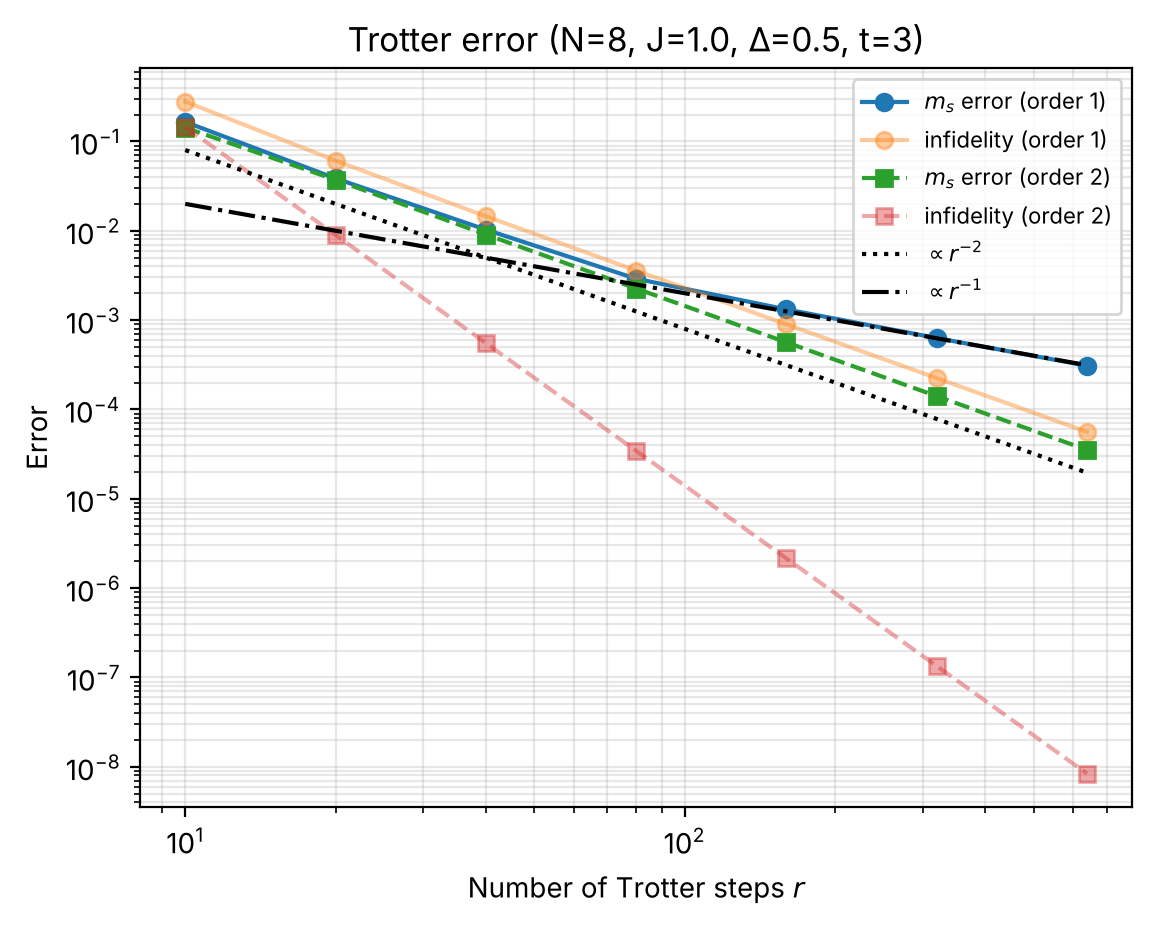

In [6]:
N = 8
J = 1.0
Delta = 0.5
t_max = 3
rs = np.array([10, 20, 40, 80, 160, 320, 640])

# 厳密な終状態 e^{-iHt}|Néel>（Qiskitの並び順で計算）
w, v = np.linalg.eigh(xxz_op(N, J, Delta).to_matrix())
psi_init = Statevector(neel_circuit(N)).data
psi_exact = v @ (np.exp(-1j * w * t_max) * (v.conj().T @ psi_init))

for order, mk in [(1, "o-"), (2, "s--")]:
    ms_err, infid = [], []
    for r in rs:
        ts_r, ms_r = ms_trotter(N, J, Delta, t_max, r, order)
        ms_ex = ms_ed(N, J, Delta, ts_r)
        ms_err.append(np.max(np.abs(ms_r - ms_ex)))
        sv = Statevector(neel_circuit(N))
        step = xxz_trotter_step(N, J, Delta, t_max / r, order)
        for _ in range(r):
            sv = sv.evolve(step)
        infid.append(1 - abs(np.vdot(psi_exact, sv.data))**2)
    plt.loglog(rs, ms_err, mk, label=rf"$m_s$ error (order {order})")
    plt.loglog(rs, infid, mk, alpha=0.4, label=f"infidelity (order {order})")
    print(f"{order}次: m_s の誤差 = {np.array(ms_err)}")

plt.loglog(rs, 8 / rs**2, "k:", label=r"$\propto r^{-2}$")
plt.loglog(rs, 0.2 / rs, "k-.", label=r"$\propto r^{-1}$")
plt.xlabel("Number of Trotter steps $r$")
plt.ylabel("Error")
plt.title(f"Trotter error (N={N}, J={J}, Δ={Delta}, t={t_max})")
plt.legend(fontsize=8)
plt.grid(which="both", alpha=0.3)
plt.show()

- **2次の分解**：$m_s$の誤差は$r^{-2}$に、不忠実度は$r^{-4}$に比例して小さくなる。
- **1次の分解**：$r$が小さいうちは$m_s$の誤差も2次とほぼ同じで$r^{-2}$のように減るが、$r$が大きくなると$r^{-1}$に比例する項が残り、2次との差が開いていく。不忠実度は$r^{-2}$である。

これは[03_trotter.ipynb](03_trotter.ipynb)の2節の式$(E_{\delta t/2}OE_{\delta t/2})^r = E_{\delta t/2}(OE_{\delta t})^rE_{-\delta t/2}$の通りで、1次の分解の誤差は「時間とともに積み重なる$O(\delta t^2)$の誤差」と「最初と最後の$e^{\pm iH_{\mathrm{even}}\delta t/2}$による、積み重ならない$O(\delta t)$の誤差」の和になっている。

TFIMでは1次と2次の分解で$m_x$が完全に一致したが、XXZ模型ではNéel状態が$H_{\mathrm{even}}$の固有状態でないため一致しない。同じ精度を得るのに必要なステップ数は2次の方が少なく、1ステップあたりのゲート数はほとんど変わらない（両端の半分のステップの分だけ増える）ので、XXZ模型では2次の分解を使う方が得である。

## 6. 測定のサンプリングによる推定

実際の量子コンピュータと同じように、**測定のサンプリング**で$m_s$を推定してみる。$M_s$は$Z$基底でそのまま測れるので、測定の前に基底を変えるゲートは要らない。各ショットのビット列$b_{n-1}\cdots b_1b_0$（Qiskitでは右端が量子ビット0）から$\frac{1}{n}\sum_j(-1)^j(1-2b_j)$を計算し、平均をとる。

全磁化が保存するので、雑音のない回路ではどのショットでも$\sum_j(1-2b_j) = 0$になる。実機ではこれが0でないショットを捨てる（ポストセレクション）ことで、雑音の一部を取り除ける。ここでは雑音のないシミュレーションなので、そのようなショットが現れないことも確かめる。

全磁化が 0 でないショットの数 = 0


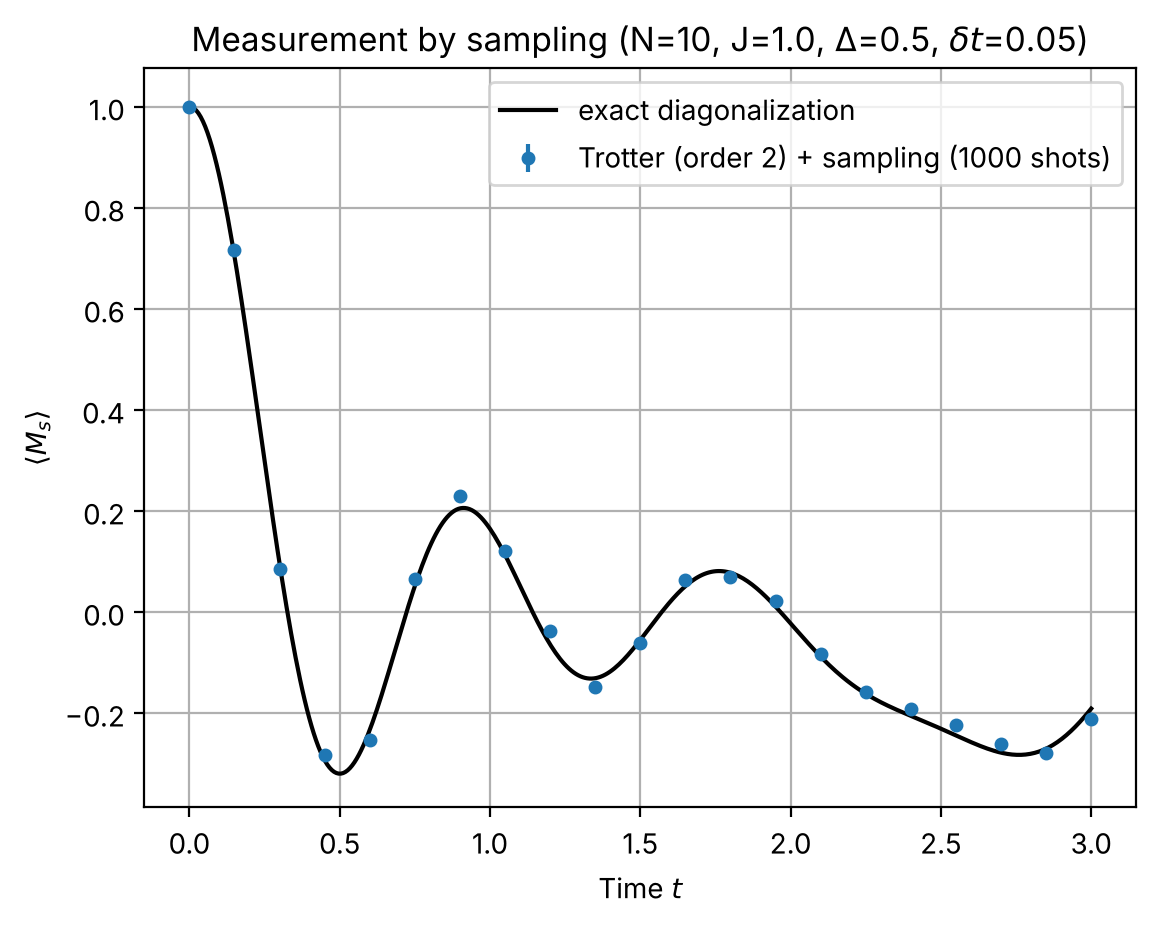

In [7]:
N = 10
J = 1.0
Delta = 0.5
t_max = 3
r = 60
shots = 1000
rng_seed = 1

dt = t_max / r
step = xxz_trotter_step(N, J, Delta, dt, order=2)
signs = (-1.0) ** np.arange(N)

sv = Statevector(neel_circuit(N))
sv.seed(rng_seed)
ts_shot, ms_shot, n_bad = [], [], 0
for k in range(r + 1):
    if k % 3 == 0:
        counts = sv.sample_counts(shots)   # Z基底で shots 回測定
        total = 0.0
        for bits, cnt in counts.items():
            z = np.array([1 - 2 * int(bits[N - 1 - j]) for j in range(N)])   # bits の右端が量子ビット0
            if z.sum() != 0:
                n_bad += cnt                # 全磁化が 0 でないショット（雑音がなければ現れない）
            total += cnt * np.dot(signs, z) / N
        ts_shot.append(k * dt)
        ms_shot.append(total / shots)
    sv = sv.evolve(step)
print(f"全磁化が 0 でないショットの数 = {n_bad}")

ts = np.linspace(0, t_max, 400)
plt.plot(ts, ms_ed(N, J, Delta, ts), "k-", label="exact diagonalization")
plt.errorbar(ts_shot, ms_shot, yerr=1 / np.sqrt(shots * N), fmt="o", ms=4, label=f"Trotter (order 2) + sampling ({shots} shots)")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Measurement by sampling (N={N}, J={J}, Δ={Delta}, $\\delta t$={dt})")
plt.legend()
plt.grid()
plt.show()

有限回の測定による統計的なばらつきはあるが、厳密な値を再現している（エラーバーは統計誤差の目安$1/\sqrt{N_{\mathrm{shot}}\,n}$）。全磁化が0でないショットは1つも現れず、回路が全磁化を厳密に保存していることも確かめられた。

## まとめ

- $\Delta=0$では、厳密対角化とJordan-Wigner変換の$m_s(t)$は数値誤差の範囲で一致し、大きな$n$では無限に長い鎖の結果$J_0(8Jt)$に近づく。
- $\Delta\neq0$ではJordan-Wigner変換が使えないので、全磁化のブロックを使った厳密対角化で$n=14$まで調べた。$\Delta<1$では振動しながら0に減衰し、$\Delta>1$では反強磁性の秩序が長く残る。有限サイズの影響は$t\approx1$〜$2$あたりから現れる。
- Trotter分解は偶数ボンドと奇数ボンドに分けて行い、$\delta t$を小さくすれば厳密な結果に近づく。TFIMと違い1次と2次の分解は一致せず、1次の分解には積み重ならない$O(\delta t)$の誤差が残るので、2次の分解の方が効率がよい。
- 回路は全磁化を厳密に保存するので、$Z$基底のサンプリングでそのまま$m_s$を推定でき、実機では全磁化によるポストセレクションも使える。